# Diabetes Prediction using Logistic Regression
**Unlox AI & ML Cohort — Minor Project 3**  
**Author:** Chaitanya Rao Solapurkar  
**Student ID:** 20522493  
**Date:** October 2026  
**Dataset:** Pima Indians Diabetes Database (Kaggle: `diabetes.csv`)  

---

### Project Overview
The goal of this project is to build an interpretable, diagnostic classification model that predicts whether a patient has diabetes (`Outcome = 1`) or not (`Outcome = 0`) based on baseline clinical measurements.

In healthcare screening, missing a diabetic patient (a **False Negative**) carries severe consequences, as undetected hyperglycemia can lead to long-term renal, cardiovascular, and neurological damage. Conversely, a **False Positive** only causes a patient to undergo a harmless confirmatory lab test. For this reason, our modeling strategy prioritizes **Recall (Sensitivity)** alongside overall discrimination ability (**ROC-AUC**).

### Technical Workflow
The end-to-end pipeline follows these specific steps:
1. **Load Data:** Ingest `diabetes.csv` and inspect schema and summary statistics.
2. **Handle Invalid Zeros:** Identify physiologically impossible values in clinical features and treat them as missing data.
3. **Train-Test Split:** Perform a stratified 80:20 split before any transformations to prevent data leakage.
4. **Median Imputation:** Fill missing values using training set medians (robust to skewed distributions).
5. **Feature Scaling:** Standardize features with `StandardScaler` to ensure fair weighting in logistic optimization.
6. **Train Logistic Regression:** Fit a logistic model using `class_weight='balanced'` to offset class imbalance.
7. **Evaluate Performance:** Measure Accuracy, Precision, Recall, F1-Score, ROC-AUC, and inspect the Confusion Matrix.
8. **Interpret Coefficients:** Quantify risk drivers using standardized coefficients and Odds Ratios.

## 1. Import Libraries
We import standard data science and machine learning libraries. Warnings are suppressed for clean reporting.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

# Plotting appearance
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['font.size'] = 10
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

## 2. Load and Inspect the Dataset
We load the Pima Indians Diabetes dataset from `diabetes.csv` and examine its shape, column types, and first few records.

In [2]:
# Load the dataset
df = pd.read_csv('diabetes.csv')

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset Dimensions: 768 rows, 9 columns


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.600,0.627,50,1
1,1,85,66,29,0,26.600,0.351,31,0
2,8,183,64,0,0,23.300,0.672,32,1
3,1,89,66,23,94,28.100,0.167,21,0
4,0,137,40,35,168,43.100,2.288,33,1


In [3]:
# Column info and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
# Descriptive statistics of raw features
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.000,3.845,3.370,0.000,1.000,3.000,6.000,17.000
Glucose,768.000,120.895,31.973,0.000,99.000,117.000,140.250,199.000
BloodPressure,768.000,69.105,19.356,0.000,62.000,72.000,80.000,122.000
SkinThickness,768.000,20.536,15.952,0.000,0.000,23.000,32.000,99.000
Insulin,768.000,79.799,115.244,0.000,0.000,30.500,127.250,846.000
BMI,768.000,31.993,7.884,0.000,27.300,32.000,36.600,67.100
DiabetesPedigreeFunction,768.000,0.472,0.331,0.078,0.244,0.372,0.626,2.420
Age,768.000,33.241,11.760,21.000,24.000,29.000,41.000,81.000
Outcome,768.000,0.349,0.477,0.000,0.000,0.000,1.000,1.000


### Target Class Distribution
We check the proportion of positive (diabetic) vs negative (non-diabetic) cases to assess class imbalance.

         Count  Percentage (%)
Outcome                       
0          500          65.104
1          268          34.896


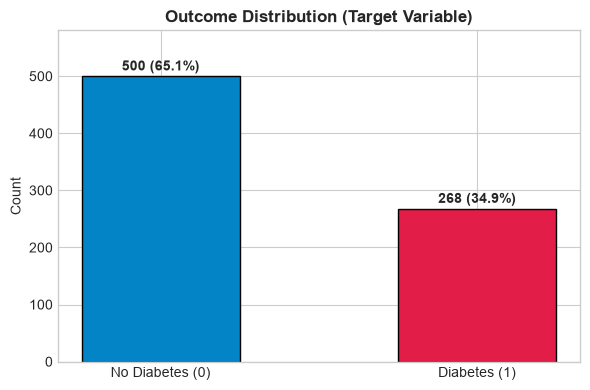

In [5]:
# Check target class counts
outcome_counts = df['Outcome'].value_counts()
outcome_pct = df['Outcome'].value_counts(normalize=True) * 100

summary_target = pd.DataFrame({
    'Count': outcome_counts,
    'Percentage (%)': outcome_pct
})
print(summary_target)

# Visualize target distribution
plt.figure(figsize=(6, 4))
bars = plt.bar(['No Diabetes (0)', 'Diabetes (1)'], outcome_counts, color=['#0284c7', '#e11d48'], width=0.5, edgecolor='black')
plt.title('Outcome Distribution (Target Variable)', fontweight='bold')
plt.ylabel('Count')
for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, y + 10, f'{y} ({y/len(df)*100:.1f}%)', ha='center', fontweight='bold')
plt.ylim(0, 580)
plt.tight_layout()
plt.show()

## 3. Data Hygiene: Handling Physiologically Invalid Zeros
In human physiology, blood glucose concentration, resting blood pressure, triceps skinfold thickness, serum insulin, and body mass index (BMI) cannot be zero in living persons. 

In this dataset, zero values in these five variables represent unrecorded/missing measurements rather than true biological zeros. We identify these columns and replace the invalid zeros with `NaN`.

Note that `Pregnancies` can legitimately be zero for women who have never been pregnant, and neither `Age` nor `DiabetesPedigreeFunction` contain zeros.

In [6]:
# Features where zero is physiologically impossible
zero_columns = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# Count invalid zeros
zero_counts = {col: (df[col] == 0).sum() for col in zero_columns}
zero_percentages = {col: ((df[col] == 0).sum() / len(df)) * 100 for col in zero_columns}

zero_audit = pd.DataFrame({
    'Zero Count': zero_counts,
    'Missing Percentage (%)': zero_percentages
}).sort_values(by='Zero Count', ascending=False)

print("Physiologically Invalid Zero Counts:")
print(zero_audit)

Physiologically Invalid Zero Counts:
               Zero Count  Missing Percentage (%)
Insulin               374                  48.698
SkinThickness         227                  29.557
BloodPressure          35                   4.557
BMI                    11                   1.432
Glucose                 5                   0.651


In [7]:
# Replace zeros with NaN in designated features
df_clean = df.copy()
for col in zero_columns:
    df_clean[col] = df_clean[col].replace(0, np.nan)

# Confirm NaN conversion
print("Missing values after zero-replacement:")
print(df_clean[zero_columns].isnull().sum())

Missing values after zero-replacement:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


## 4. Correlation Analysis
With invalid zeros replaced by `NaN`, we compute the pairwise correlation matrix to see how clinical indicators relate to one another and to the diabetic outcome.

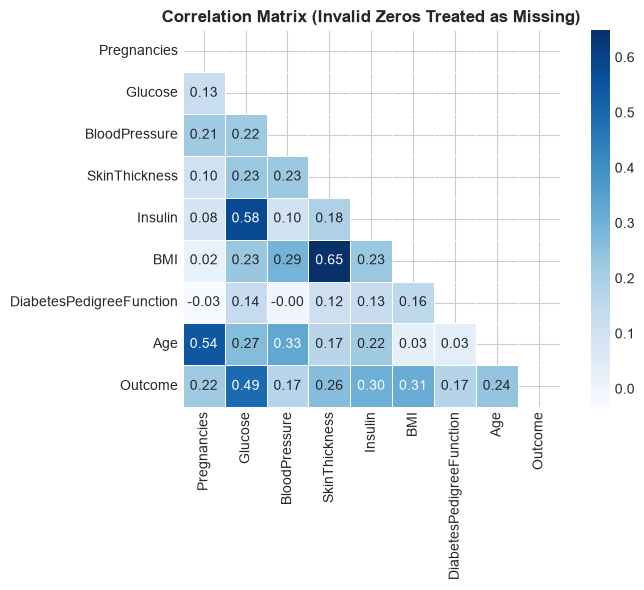

Correlation with Diabetic Outcome:
Glucose                    0.495
BMI                        0.314
Insulin                    0.303
SkinThickness              0.259
Age                        0.238
Pregnancies                0.222
DiabetesPedigreeFunction   0.174
BloodPressure              0.171
Name: Outcome, dtype: float64


In [8]:
# Pairwise correlation matrix
plt.figure(figsize=(8, 6))
corr = df_clean.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='Blues', square=True, linewidths=0.5)
plt.title('Correlation Matrix (Invalid Zeros Treated as Missing)', fontweight='bold')
plt.tight_layout()
plt.show()

# Ranking correlations with Outcome
outcome_corr = corr['Outcome'].drop('Outcome').sort_values(ascending=False)
print("Correlation with Diabetic Outcome:")
print(outcome_corr)

## 5. Train-Test Split (Preventing Data Leakage)
To ensure honest model evaluation, we split the data into **80% training** (614 rows) and **20% testing** (154 rows). 

We set `stratify=y` so that both partitions retain the exact same 35% diabetic class ratio. 

**Important:** We do not impute or scale before splitting. Imputation statistics (medians) and scaling parameters (mean and standard deviation) must be learned solely from the training set and applied to the test set to avoid **data leakage**.

In [9]:
# Separate features and target
X = df_clean.drop('Outcome', axis=1)
y = df_clean['Outcome']

# 80/20 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples ({y_train.sum()} diabetic, {(y_train == 0).sum()} non-diabetic)")
print(f"Test set:     {X_test.shape[0]} samples ({y_test.sum()} diabetic, {(y_test == 0).sum()} non-diabetic)")

Training set: 614 samples (214 diabetic, 400 non-diabetic)
Test set:     154 samples (54 diabetic, 100 non-diabetic)


## 6. Preprocessing: Median Imputation and Standardization
1. **Median Imputation (`SimpleImputer`):** We use the median rather than the mean because clinical distributions (especially Insulin and SkinThickness) are heavily skewed and contain outliers.
2. **Feature Scaling (`StandardScaler`):** Logistic regression relies on numerical optimization and regularization. Standardizing features gives each variable zero mean and unit variance ($z = \frac{x - \mu}{\sigma}$), placing all coefficients on an identical scale for direct comparison.

In [10]:
# 1. Median Imputation
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Display learned training medians
training_medians = pd.Series(imputer.statistics_, index=X.columns)
print("Learned Training Set Medians:")
print(training_medians)

Learned Training Set Medians:
Pregnancies                  3.000
Glucose                    117.000
BloodPressure               72.000
SkinThickness               29.000
Insulin                    125.000
BMI                         32.400
DiabetesPedigreeFunction     0.383
Age                         29.000
dtype: float64


In [11]:
# 2. Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

# Convert back to DataFrame for verification
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
print("Scaled feature means (approx 0):", np.round(X_train_scaled_df.mean().values, 3))
print("Scaled feature stds (approx 1):", np.round(X_train_scaled_df.std().values, 3))

Scaled feature means (approx 0): [-0. -0.  0. -0. -0.  0. -0. -0.]
Scaled feature stds (approx 1): [1.001 1.001 1.001 1.001 1.001 1.001 1.001 1.001]


## 7. Model Training: Balanced Logistic Regression
Because the non-diabetic class makes up ~65% of the data, an unweighted model can achieve misleading accuracy by favoring the majority class at the expense of missing true diabetic cases.

We configure `LogisticRegression` with `class_weight='balanced'`. This automatically weights training instances inversely to class frequencies, imposing a higher penalty for misclassifying positive (diabetic) patients and improving the model's sensitivity (Recall).

In [12]:
# Instantiate and train balanced Logistic Regression
lr = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
lr.fit(X_train_scaled, y_train)

print(f"Model Intercept: {lr.intercept_[0]:.4f}")
print("Logistic Regression model trained successfully.")

Model Intercept: -0.2570
Logistic Regression model trained successfully.


## 8. Model Evaluation on Test Set
We evaluate the model on the unseen test set ($N = 154$). We generate discrete class predictions (`y_pred`) and continuous prediction probabilities (`y_prob`).

In [13]:
# Predictions and predicted probabilities
y_pred = lr.predict(X_test_scaled)
y_prob = lr.predict_proba(X_test_scaled)[:, 1]

# Compute test metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

metrics_table = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'],
    'Result': [f'{acc:.3f}', f'{prec:.3f}', f'{rec:.3f}', f'{f1:.3f}', f'{roc_auc:.3f}'],
    'Meaning': [
        'Overall correct predictions',
        'Reliability of positive predictions',
        'Actual positive cases detected',
        'Balance of precision and recall',
        'Overall class-separation ability'
    ]
})
print("Evaluation Metrics Summary:")
print(metrics_table.to_string(index=False))

Evaluation Metrics Summary:
   Metric Result                             Meaning
 Accuracy  0.734         Overall correct predictions
Precision  0.603 Reliability of positive predictions
   Recall  0.704      Actual positive cases detected
 F1-score  0.650     Balance of precision and recall
  ROC-AUC  0.813    Overall class-separation ability


In [14]:
# Detailed classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['No Diabetes (0)', 'Diabetes (1)']))

Classification Report:
                 precision    recall  f1-score   support

No Diabetes (0)       0.82      0.75      0.79       100
   Diabetes (1)       0.60      0.70      0.65        54

       accuracy                           0.73       154
      macro avg       0.71      0.73      0.72       154
   weighted avg       0.75      0.73      0.74       154



### Confusion Matrix
The confusion matrix shows the breakdown of True Negatives, False Positives, False Negatives, and True Positives.

Confusion Matrix Counts:
True Negatives  (TN): 75
False Positives (FP): 25
False Negatives (FN): 16
True Positives  (TP): 38


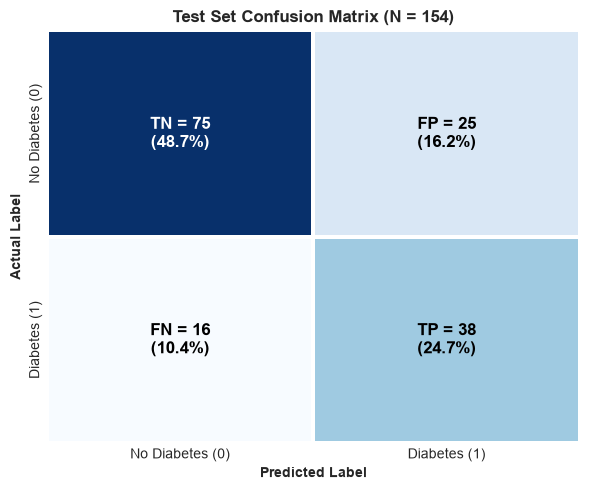

In [15]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"Confusion Matrix Counts:")
print(f"True Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")

# Visualize confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=False, cmap='Blues', cbar=False, linewidths=1.5, linecolor='white')
annotations = [
    [f"TN = {tn}\n({tn/154*100:.1f}%)", f"FP = {fp}\n({fp/154*100:.1f}%)"],
    [f"FN = {fn}\n({fn/154*100:.1f}%)", f"TP = {tp}\n({tp/154*100:.1f}%)"]
]
for i in range(2):
    for j in range(2):
        color = 'white' if cm[i, j] > 50 else 'black'
        plt.text(j + 0.5, i + 0.5, annotations[i][j], ha='center', va='center', fontsize=12, fontweight='bold', color=color)

plt.xlabel('Predicted Label', fontweight='bold')
plt.ylabel('Actual Label', fontweight='bold')
plt.xticks([0.5, 1.5], ['No Diabetes (0)', 'Diabetes (1)'])
plt.yticks([0.5, 1.5], ['No Diabetes (0)', 'Diabetes (1)'], va='center')
plt.title('Test Set Confusion Matrix (N = 154)', fontweight='bold')
plt.tight_layout()
plt.show()

### Diagnostic Curves: ROC Curve and Precision-Recall Curve

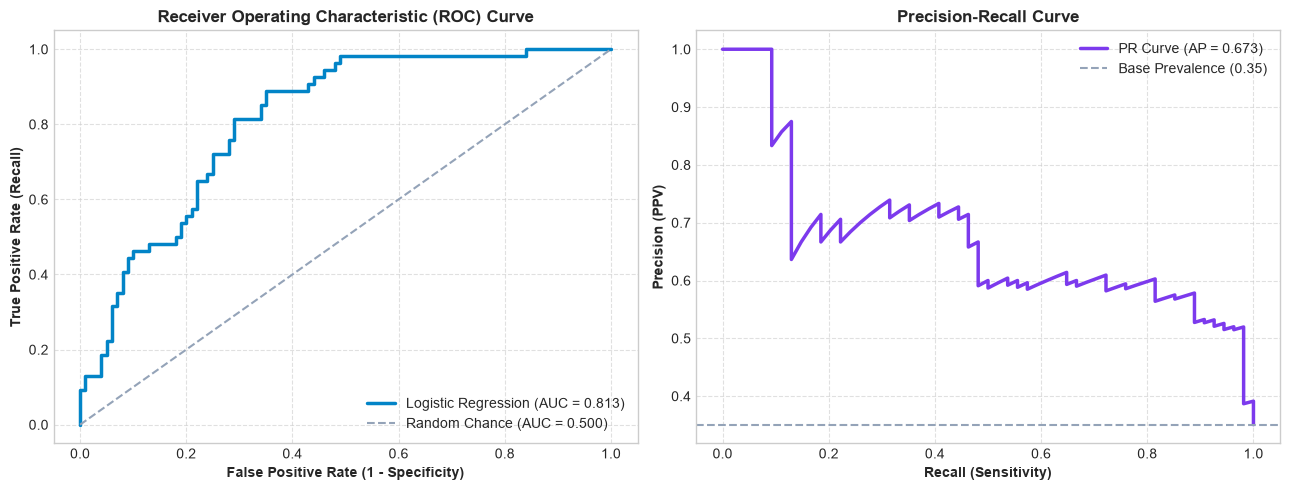

In [16]:
# ROC and PR curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[0].plot(fpr, tpr, color='#0284c7', lw=2.5, label=f'Logistic Regression (AUC = {roc_auc:.3f})')
axes[0].plot([0, 1], [0, 1], color='#94a3b8', linestyle='--', label='Random Chance (AUC = 0.500)')
axes[0].set_xlabel('False Positive Rate (1 - Specificity)', fontweight='bold')
axes[0].set_ylabel('True Positive Rate (Recall)', fontweight='bold')
axes[0].set_title('Receiver Operating Characteristic (ROC) Curve', fontweight='bold')
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. Precision-Recall Curve
prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_prob)
ap = average_precision_score(y_test, y_prob)
axes[1].plot(rec_curve, prec_curve, color='#7c3aed', lw=2.5, label=f'PR Curve (AP = {ap:.3f})')
axes[1].axhline(y_test.sum() / len(y_test), color='#94a3b8', linestyle='--', label=f'Base Prevalence ({y_test.sum()/len(y_test):.2f})')
axes[1].set_xlabel('Recall (Sensitivity)', fontweight='bold')
axes[1].set_ylabel('Precision (PPV)', fontweight='bold')
axes[1].set_title('Precision-Recall Curve', fontweight='bold')
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 9. Model Interpretation: Coefficients and Odds Ratios
Because features were standardized before model fitting, each coefficient represents the change in log-odds of having diabetes associated with a 1 standard deviation increase in that feature.

By exponentiating the coefficients ($\text{Odds Ratio} = e^{\beta}$), we convert log-odds into multiplicative changes in odds:
- $\text{OR} > 1$: Feature increases the odds of diabetes (risk factor).
- $\text{OR} = 1$: Feature has no effect.
- $\text{OR} < 1$: Feature decreases the odds of diabetes.

Feature Coefficients and Odds Ratios:
                          Coefficient (Log-Odds)  Odds Ratio (OR)
Glucose                                    1.183            3.266
BMI                                        0.710            2.033
Pregnancies                                0.373            1.452
DiabetesPedigreeFunction                   0.288            1.333
Age                                        0.186            1.205
SkinThickness                              0.014            1.014
BloodPressure                             -0.015            0.985
Insulin                                   -0.045            0.956


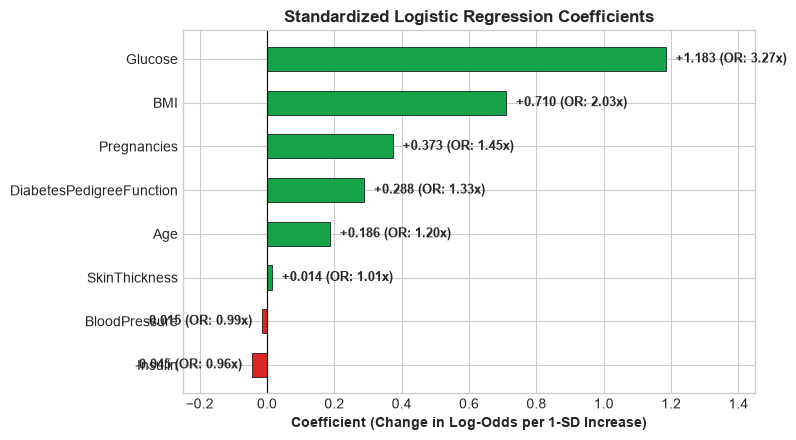

In [17]:
# Extract coefficients and compute odds ratios
coef_series = pd.Series(lr.coef_[0], index=X.columns)
odds_ratios = np.exp(coef_series)

interpretation_df = pd.DataFrame({
    'Coefficient (Log-Odds)': coef_series,
    'Odds Ratio (OR)': odds_ratios
}).sort_values(by='Coefficient (Log-Odds)', ascending=False)

print("Feature Coefficients and Odds Ratios:")
print(interpretation_df)

# Visualize feature importance
plt.figure(figsize=(8, 4.5))
sorted_df = interpretation_df.sort_values(by='Coefficient (Log-Odds)', ascending=True)
bar_colors = ['#16a34a' if c > 0 else '#dc2626' for c in sorted_df['Coefficient (Log-Odds)']]
bars = plt.barh(sorted_df.index, sorted_df['Coefficient (Log-Odds)'], color=bar_colors, height=0.55, edgecolor='black', linewidth=0.5)
plt.axvline(0, color='black', linestyle='-', linewidth=0.8)
plt.title('Standardized Logistic Regression Coefficients', fontweight='bold')
plt.xlabel('Coefficient (Change in Log-Odds per 1-SD Increase)', fontweight='bold')

for bar, (_, row) in zip(bars, sorted_df.iterrows()):
    val = row['Coefficient (Log-Odds)']
    or_val = row['Odds Ratio (OR)']
    offset = 0.03 if val >= 0 else -0.03
    ha = 'left' if val >= 0 else 'right'
    plt.text(val + offset, bar.get_y() + bar.get_height()/2, f'{val:+.3f} (OR: {or_val:.2f}x)', ha=ha, va='center', fontweight='bold', fontsize=9)

plt.xlim(-0.25, 1.45)
plt.tight_layout()
plt.show()

## 10. Key Findings, Limitations and Conclusion

### Key Findings
1. **Model Performance:** The balanced logistic regression model achieves an **ROC-AUC of 0.813**, demonstrating solid discriminatory capability on the unseen test set.
2. **High Screening Sensitivity (Recall = 70.4%):** By applying `class_weight='balanced'`, the model successfully identifies **38 out of 54** true diabetic patients in the test split. 
3. **Primary Biological Drivers:**
   - **Glucose** is by far the strongest predictor ($\beta = +1.183$, $\text{OR} = 3.27$). For each standard deviation increase in plasma glucose, the odds of diabetes more than triple.
   - **BMI** is the second strongest risk factor ($\beta = +0.710$, $\text{OR} = 2.03$), doubling the odds of diabetes per standard deviation increase.
   - **Pregnancies** ($\text{OR} = 1.45$) and **Diabetes Pedigree Function** ($\text{OR} = 1.33$) also contribute meaningful positive risk.
4. **Physiological Note on Insulin:** Insulin exhibited a slight negative coefficient ($\beta = -0.045$, $\text{OR} = 0.96$). This occurs because glucose and insulin are biologically correlated; once glucose and BMI are already conditioned on, basal insulin alone does not contribute independent additive risk in this linear log-odds model.

### Clinical Trade-offs: Recall vs. Precision
In medical screening, false negatives are far more costly than false positives:
- A **False Negative (FN = 16)** means a diabetic patient is told they are healthy, delaying essential glycemic management and increasing the likelihood of chronic complications.
- A **False Positive (FP = 25)** means a healthy person is flagged for further testing, which is safely cleared with a routine fasting blood sugar test.

Hence, accepting a precision of 60.3% to achieve a recall of 70.4% is an appropriate clinical trade-off for a primary screening tool.

### Dataset Limitations
1. **Specific Demographic:** The dataset consists solely of adult female patients of Pima Indian heritage aged 21 and older. Findings cannot be generalized to diverse populations without multi-cohort testing.
2. **Missing Clinical Data:** Key variables like Insulin (48.7% missing) and SkinThickness (29.6% missing) had substantial missingness that was imputed with medians.
3. **Sample Size:** With only 768 total records, this project serves as an educational demonstration of classification concepts and should not be used as a standalone diagnostic tool without physician oversight.